## Week 6 Safola Bhattarai 

### Collecting Documents

In [1]:
import os, re, math, time
from collections import defaultdict, Counter
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")
DATA_DIR = "newsgroups"

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Asus\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


### Loading Dataset 

In [2]:
documents, labels = {}, {}

for fname in sorted(os.listdir(DATA_DIR)):
    if not fname.endswith(".txt"):
        continue
    group = fname[:-4]
    with open(os.path.join(DATA_DIR, fname), encoding="latin-1") as f:
        raw = f.read()
    posts = re.split(r"^Newsgroup: .*\n", raw, flags=re.M)
    for post in posts:
        m = re.match(r"document_id: (\d+)", post)
        if not m:
            continue
        doc_id = int(m.group(1))
        subject = re.search(r"^Subject: (.*)$", post, flags=re.M)
        body = post.split("\n\n", 1)[1] if "\n\n" in post else ""
        body = "\n".join(l for l in body.split("\n") if not l.strip().startswith(">"))
        text = ((subject.group(1) if subject else "") + " " + body).strip()
        if len(text.split()) >= 10:
            documents[doc_id] = text
            labels[doc_id] = group

print("Total documents:", len(documents))
print("Newsgroups:", len(set(labels.values())))
for g, c in sorted(Counter(labels.values()).items()):
    print(f"  {g:30s} {c}")

Total documents: 15343
Newsgroups: 20
  alt.atheism                    477
  comp.graphics                  969
  comp.os.ms-windows.misc        979
  comp.sys.ibm.pc.hardware       403
  comp.sys.mac.hardware          954
  comp.windows.x                 970
  misc.forsale                   375
  rec.autos                      853
  rec.motorcycles                269
  rec.sport.baseball             990
  rec.sport.hockey               165
  sci.crypt                      990
  sci.electronics                741
  sci.med                        985
  sci.space                      983
  soc.religion.christian         996
  talk.politics.guns             908
  talk.politics.mideast          937
  talk.politics.misc             774
  talk.religion.misc             625


### Preprocessing

In [3]:
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()
stem_cache = {}

def preprocess(text):
    text = text.lower()
    text = re.sub(r"\S+@\S+", " ", text)      # remove email addresses
    text = re.sub(r"[^a-z\s]", " ", text)     # remove punctuation/numbers
    tokens = []
    for t in text.split():
        if len(t) > 2 and t not in stop_words:
            if t not in stem_cache:
                stem_cache[t] = stemmer.stem(t)
            tokens.append(stem_cache[t])
    return tokens

demo = "NASA is launching the Space Shuttle tomorrow, contact nasa@gov.com"
print("Before:", demo)
print("After :", preprocess(demo))

Before: NASA is launching the Space Shuttle tomorrow, contact nasa@gov.com
After : ['nasa', 'launch', 'space', 'shuttl', 'tomorrow', 'contact']


### Inverted Index

In [4]:
inverted_index = defaultdict(dict)   # term -> {doc_id: term frequency}
doc_len = {}

start = time.time()
for doc_id, text in documents.items():
    tokens = preprocess(text)
    doc_len[doc_id] = len(tokens)
    for term, tf in Counter(tokens).items():
        inverted_index[term][doc_id] = tf

N = len(documents)
avg_dl = sum(doc_len.values()) / N
df = {t: len(p) for t, p in inverted_index.items()}

print("Index built in", round(time.time() - start, 1), "seconds")
print("Documents:", N)
print("Vocabulary size:", len(inverted_index))
print("Average doc length:", round(avg_dl, 1))
print("Postings for 'space':", len(inverted_index["space"]), "documents")

Index built in 7.5 seconds
Documents: 15343
Vocabulary size: 66597
Average doc length: 113.8
Postings for 'space': 777 documents


### Boolean Retrival

In [5]:
ALL_DOCS = set(documents)

def term_docs(term):
    return set(inverted_index.get(stemmer.stem(term.lower()), {}))

def boolean_search(query):
    """Supports AND, OR, NOT. Precedence: NOT > AND > OR."""
    result = set()
    for or_part in query.split(" OR "):
        part_docs = set(ALL_DOCS)
        for term in or_part.split(" AND "):
            term = term.strip()
            if term.startswith("NOT "):
                part_docs -= term_docs(term[4:])
            else:
                part_docs &= term_docs(term)
        result |= part_docs
    return sorted(result)

for q in ["nasa AND shuttle", "nasa OR hockey", "nasa AND NOT shuttle", "encryption AND clipper"]:
    hits = boolean_search(q)
    print(f"{q:28s} -> {len(hits)} posts", Counter(labels[d] for d in hits).most_common(2))

nasa AND shuttle             -> 68 posts [('sci.space', 63), ('comp.graphics', 5)]
nasa OR hockey               -> 327 posts [('sci.space', 173), ('rec.sport.hockey', 52)]
nasa AND NOT shuttle         -> 191 posts [('sci.space', 110), ('comp.windows.x', 14)]
encryption AND clipper       -> 229 posts [('sci.crypt', 223), ('talk.politics.guns', 5)]


### TF-IDF with Cosine similarity 

In [6]:
def tfidf_weight(tf, term):
    return (1 + math.log(tf)) * math.log(N / df[term])

doc_norm = defaultdict(float)
for term, postings in inverted_index.items():
    for d, tf in postings.items():
        doc_norm[d] += tfidf_weight(tf, term) ** 2
doc_norm = {d: math.sqrt(v) for d, v in doc_norm.items()}

def search_tfidf(query, k=10):
    q_tf = Counter(preprocess(query))
    scores = defaultdict(float)
    q_norm = 0
    for term, tf in q_tf.items():
        if term not in inverted_index:
            continue
        wq = tfidf_weight(tf, term)
        q_norm += wq ** 2
        for d, dtf in inverted_index[term].items():
            scores[d] += wq * tfidf_weight(dtf, term)
    q_norm = math.sqrt(q_norm) or 1
    ranked = {d: s / (doc_norm[d] * q_norm) for d, s in scores.items() if doc_norm.get(d, 0) > 0}
    return sorted(ranked.items(), key=lambda x: -x[1])[:k]

for d, s in search_tfidf("nasa space shuttle launch", 3):
    print(f"Doc {d} [{labels[d]}] score={s:.3f}")

Doc 61532 [sci.space] score=0.436
Doc 61199 [sci.space] score=0.372
Doc 61146 [sci.space] score=0.347


### BM25

In [7]:
def search_bm25(query, k=10, k1=1.5, b=0.75):
    scores = defaultdict(float)
    for term in set(preprocess(query)):
        if term not in inverted_index:
            continue
        idf = math.log((N - df[term] + 0.5) / (df[term] + 0.5) + 1)
        for d, tf in inverted_index[term].items():
            denom = tf + k1 * (1 - b + b * doc_len[d] / avg_dl)
            scores[d] += idf * tf * (k1 + 1) / denom
    return sorted(scores.items(), key=lambda x: -x[1])[:k]

for d, s in search_bm25("nasa space shuttle launch", 3):
    print(f"Doc {d} [{labels[d]}] score={s:.2f}")

Doc 61525 [sci.space] score=26.08
Doc 61146 [sci.space] score=24.88
Doc 61214 [sci.space] score=24.66


### Test Query and sample quuery results 

In [9]:
test_queries = [
    ("atheism arguments for the existence of god", "alt.atheism"),
    ("evidence against religion and belief", "alt.atheism"),
    ("rendering 3d graphics image file format", "comp.graphics"),
    ("software to convert and display images", "comp.graphics"),
    ("windows driver problem installing", "comp.os.ms-windows.misc"),
    ("how to run dos programs in windows", "comp.os.ms-windows.misc"),
    ("pc hard drive controller scsi ide", "comp.sys.ibm.pc.hardware"),
    ("motherboard cpu upgrade speed", "comp.sys.ibm.pc.hardware"),
    ("apple macintosh powerbook problem", "comp.sys.mac.hardware"),
    ("mac monitor and memory upgrade", "comp.sys.mac.hardware"),
    ("x window system motif widget server", "comp.windows.x"),
    ("xterm display configuration", "comp.windows.x"),
    ("for sale price offer shipping", "misc.forsale"),
    ("selling used equipment best offer", "misc.forsale"),
    ("car engine buying a used automobile", "rec.autos"),
    ("brakes and tires on my car", "rec.autos"),
    ("motorcycle riding helmet bike", "rec.motorcycles"),
    ("harley honda bike engine", "rec.motorcycles"),
    ("baseball pitcher batting season", "rec.sport.baseball"),
    ("world series team home run", "rec.sport.baseball"),
    ("hockey nhl playoff goalie", "rec.sport.hockey"),
    ("stanley cup team game score", "rec.sport.hockey"),
    ("encryption key algorithm security", "sci.crypt"),
    ("clipper chip government wiretap", "sci.crypt"),
    ("circuit voltage resistor electronics", "sci.electronics"),
    ("building an amplifier with transistors", "sci.electronics"),
    ("doctor patient disease treatment", "sci.med"),
    ("medical symptoms medicine drug", "sci.med"),
    ("nasa space shuttle launch orbit", "sci.space"),
    ("moon mars satellite rocket", "sci.space"),
    ("jesus christ bible church faith", "soc.religion.christian"),
    ("christian god salvation scripture", "soc.religion.christian"),
    ("gun control firearms weapons law", "talk.politics.guns"),
    ("second amendment rifle handgun", "talk.politics.guns"),
    ("israel arab peace palestinian", "talk.politics.mideast"),
    ("turkish armenian middle east conflict", "talk.politics.mideast"),
    ("president clinton government tax policy", "talk.politics.misc"),
    ("political debate congress economy", "talk.politics.misc"),
    ("religious beliefs and moral discussion", "talk.religion.misc"),
    ("spirituality faith and church doctrine", "talk.religion.misc"),
]

relevant_by_group = defaultdict(set)
for d, g in labels.items():
    relevant_by_group[g].add(d)

print(len(test_queries), "queries across", len(set(g for _, g in test_queries)), "newsgroups")



q_text, q_group = test_queries[28]
print("QUERY:", q_text, "| target group:", q_group, "\n")

for name, fn in [("TF-IDF", search_tfidf), ("BM25", search_bm25)]:
    print(f"--- {name} top 5 ---")
    for rank, (d, s) in enumerate(fn(q_text, 5), 1):
        ok = "RELEVANT" if labels[d] == q_group else "not relevant"
        print(f"{rank}. Doc {d} [{labels[d]}] score={s:.3f} {ok}")
        print("    ", documents[d][:90].replace("\n", " "))

40 queries across 20 newsgroups
QUERY: nasa space shuttle launch orbit | target group: sci.space 

--- TF-IDF top 5 ---
1. Doc 61532 [sci.space] score=0.388 RELEVANT
     Re: Political banner in space  Well,  you better not get the shuttle as your launch vehicl
2. Doc 60854 [sci.space] score=0.370 RELEVANT
     Space Shuttle information wanted   Hello everyone,  	I was hoping someone could help me ou
3. Doc 61525 [sci.space] score=0.347 RELEVANT
     Re: Single Launch Space Station : Andy Cohen <Cohen@ssdgwy.mdc.com> writes: : >the Single 
4. Doc 61199 [sci.space] score=0.330 RELEVANT
     How can you see the launch of the Space Shuttle ?  Sorry for asking a question that's not 
5. Doc 61146 [sci.space] score=0.308 RELEVANT
     Weekly reminder for Frequently Asked Questions list     This notice will be posted weekly 
--- BM25 top 5 ---
1. Doc 61525 [sci.space] score=32.149 RELEVANT
     Re: Single Launch Space Station : Andy Cohen <Cohen@ssdgwy.mdc.com> writes: : >the Single 
2. Doc 5

### Evaluation

In [10]:
def precision_at_k(ranked, rel, k):
    return sum(1 for d in ranked[:k] if d in rel) / k

def reciprocal_rank(ranked, rel):
    for i, d in enumerate(ranked, 1):
        if d in rel:
            return 1 / i
    return 0

def average_precision_at_k(ranked, rel, k=100):
    hits, total = 0, 0
    for i, d in enumerate(ranked[:k], 1):
        if d in rel:
            hits += 1
            total += hits / i
    return total / min(len(rel), k)

def evaluate(search_fn):
    P10, P50, RR, AP = [], [], [], []
    for q, g in test_queries:
        rel = relevant_by_group[g]
        ranked = [d for d, _ in search_fn(q, k=100)]
        P10.append(precision_at_k(ranked, rel, 10))
        P50.append(precision_at_k(ranked, rel, 50))
        RR.append(reciprocal_rank(ranked, rel))
        AP.append(average_precision_at_k(ranked, rel, 100))
    return [np.mean(P10), np.mean(P50), np.mean(RR), np.mean(AP)]

results = {}
print(f"{'Model':8s} {'P@10':>6s} {'P@50':>6s} {'MRR':>6s} {'MAP@100':>8s}")
for name, fn in [("TF-IDF", search_tfidf), ("BM25", search_bm25)]:
    results[name] = evaluate(fn)
    r = results[name]
    print(f"{name:8s} {r[0]:6.3f} {r[1]:6.3f} {r[2]:6.3f} {r[3]:8.3f}")

Model      P@10   P@50    MRR  MAP@100
TF-IDF    0.770  0.734  0.902    0.568
BM25      0.820  0.747  0.910    0.604


### Comparison Chart

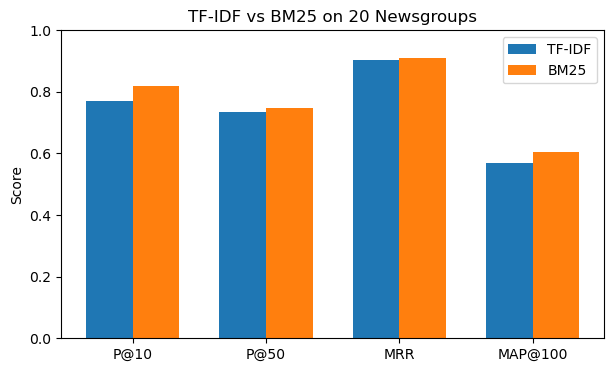

In [11]:
metrics = ["P@10", "P@50", "MRR", "MAP@100"]
x = np.arange(len(metrics)); w = 0.35
plt.figure(figsize=(7, 4))
plt.bar(x - w/2, results["TF-IDF"], w, label="TF-IDF")
plt.bar(x + w/2, results["BM25"], w, label="BM25")
plt.xticks(x, metrics); plt.ylabel("Score"); plt.ylim(0, 1)
plt.title("TF-IDF vs BM25 on 20 Newsgroups"); plt.legend()
plt.savefig("retrieval_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Per-newsgroup Analysis 

In [12]:
bm_p10 = defaultdict(list)
for q, g in test_queries:
    ranked = [d for d, _ in search_bm25(q, k=10)]
    bm_p10[g].append(precision_at_k(ranked, relevant_by_group[g], 10))

for g in sorted(bm_p10):
    print(f"{g:28s} {np.mean(bm_p10[g]):.2f}")

alt.atheism                  0.50
comp.graphics                0.95
comp.os.ms-windows.misc      0.90
comp.sys.ibm.pc.hardware     0.55
comp.sys.mac.hardware        0.90
comp.windows.x               1.00
misc.forsale                 0.75
rec.autos                    0.85
rec.motorcycles              1.00
rec.sport.baseball           0.95
rec.sport.hockey             0.90
sci.crypt                    0.95
sci.electronics              0.95
sci.med                      1.00
sci.space                    1.00
soc.religion.christian       0.70
talk.politics.guns           0.90
talk.politics.mideast        1.00
talk.politics.misc           0.55
talk.religion.misc           0.10
